# SHAP Explainability

## Objective

The objective of this notebook is to understand how the trained XGBoost classification model makes predictions using SHAP (SHapley Additive exPlanations).

SHAP helps explain the contribution of individual features toward a model's prediction.

This notebook focuses on:

1. Loading the preprocessed training and testing datasets.
2. Reconstructing the tuned XGBoost model.
3. Calculating SHAP values for the test dataset.
4. Understanding global feature importance.
5. Understanding feature contributions for individual predictions.
6. Visualizing explanations for the Normal, Suspect, and Pathological classes.

The goal is to make the model's predictions more interpretable rather than treating the model as a black box.

**Note:** This is an educational machine-learning prototype. SHAP explanations do not establish clinical validity and must not be interpreted as medical advice or diagnosis.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

from pathlib import Path
from xgboost import XGBClassifier

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
data_dir = Path("../data/processed")

X_train = pd.read_csv(data_dir / "X_train.csv")
X_test = pd.read_csv(data_dir / "X_test.csv")

y_train = pd.read_csv(data_dir / "y_train.csv").squeeze()
y_test = pd.read_csv(data_dir / "y_test.csv").squeeze()

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (1690, 21)
Testing data shape: (423, 21)
Training target shape: (1690,)
Testing target shape: (423,)


## Reconstructing the Tuned XGBoost Model

Based on the cross-validation results from the previous notebook, XGBoost was selected as the leading candidate.

The tuned model uses the following hyperparameters:

- Subsample: 0.7
- Number of estimators: 200
- Maximum depth: 6
- Learning rate: 0.03
- Column sampling: 1.0

We reconstruct and train the model using the training dataset.

In [4]:
tuned_xgb = XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    subsample=0.7,
    n_estimators=200,
    max_depth=6,
    learning_rate=0.03,
    colsample_bytree=1.0
)

tuned_xgb.fit(X_train, y_train)

print("Tuned XGBoost model trained successfully.")

Tuned XGBoost model trained successfully.


In [5]:
y_pred = tuned_xgb.predict(X_test)

print("Actual classes:", sorted(y_test.unique()))
print("Predicted classes:", sorted(np.unique(y_pred)))

print("\nSample predictions:")
print(y_pred[:10])

Actual classes: [np.int64(0), np.int64(1), np.int64(2)]
Predicted classes: [np.int64(0), np.int64(1), np.int64(2)]

Sample predictions:
[0 0 2 0 0 0 0 0 0 0]


## SHAP Explainer

SHAP calculates how much each feature contributes to a model's output.

For this project, we use TreeExplainer because XGBoost is a tree-based model.

We calculate SHAP values for a sample of the test dataset to understand the model's behavior.

In [22]:
explainer = shap.TreeExplainer(tuned_xgb)

X_explain = X_test.sample(
    n=min(100, len(X_test)),
    random_state=RANDOM_STATE
)

shap_explanation = explainer(X_explain)

print("SHAP values calculated successfully.")
print("SHAP values shape:", shap_explanation.values.shape)
# X_explain = X_test.copy()

# shap_explanation = explainer(X_explain)

# print("SHAP values calculated for the complete test dataset.")
# print("SHAP values shape:", shap_explanation.values.shape)

SHAP values calculated successfully.
SHAP values shape: (100, 21, 3)


## Global Feature Importance

Global feature importance helps identify which CTG features have the greatest overall influence on the model's predictions.

We calculate the mean absolute SHAP value for every feature across the explained samples and all three classes.

A higher mean absolute SHAP value indicates a greater contribution to the model's output.

In [16]:
shap_values_array = shap_explanation.values

mean_abs_shap = np.abs(shap_values_array).mean(axis=(0, 2))

feature_importance = pd.DataFrame({
    "Feature": X_explain.columns,
    "Mean Absolute SHAP Value": mean_abs_shap
})

feature_importance = feature_importance.sort_values(
    by="Mean Absolute SHAP Value",
    ascending=False
).reset_index(drop=True)

feature_importance

,Feature,Mean Absolute SHAP Value
0,abnormal_short_term_variability,0.571346
1,accelerations,0.435246
2,percentage_of_time_with_abnormal_long_term_var...,0.399012
3,histogram_median,0.243412
4,histogram_mean,0.240869
5,mean_value_of_short_term_variability,0.204337
6,prolongued_decelerations,0.169437
7,histogram_mode,0.135388
8,uterine_contractions,0.122152
9,histogram_min,0.090351


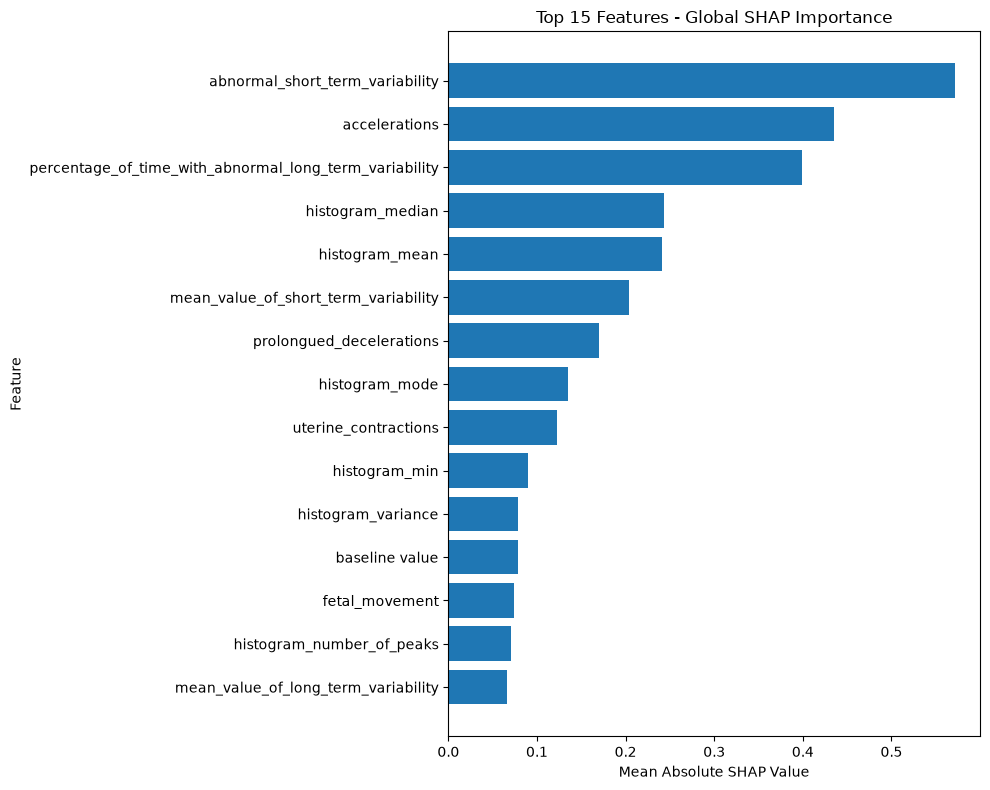

In [17]:
plt.figure(figsize=(10, 8))

plt.barh(
    feature_importance["Feature"].head(15)[::-1],
    feature_importance["Mean Absolute SHAP Value"].head(15)[::-1]
)

plt.title("Top 15 Features - Global SHAP Importance")
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

## Class-wise SHAP Analysis

The classification model predicts three classes:

- Normal
- Suspect
- Pathological

SHAP values are calculated separately for each class.

A positive SHAP value pushes the model's raw output toward the corresponding class, while a negative SHAP value pushes it away from that class.

The summary plots help us understand both the magnitude and direction of feature contributions.


SHAP Summary Plot - Normal


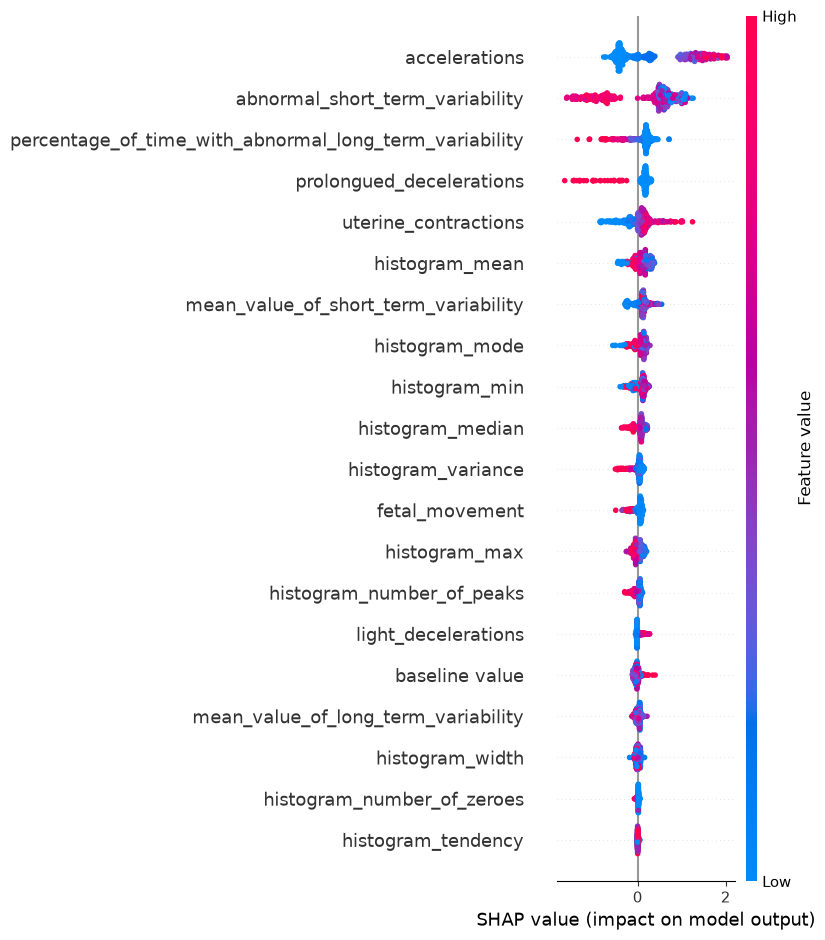


SHAP Summary Plot - Suspect


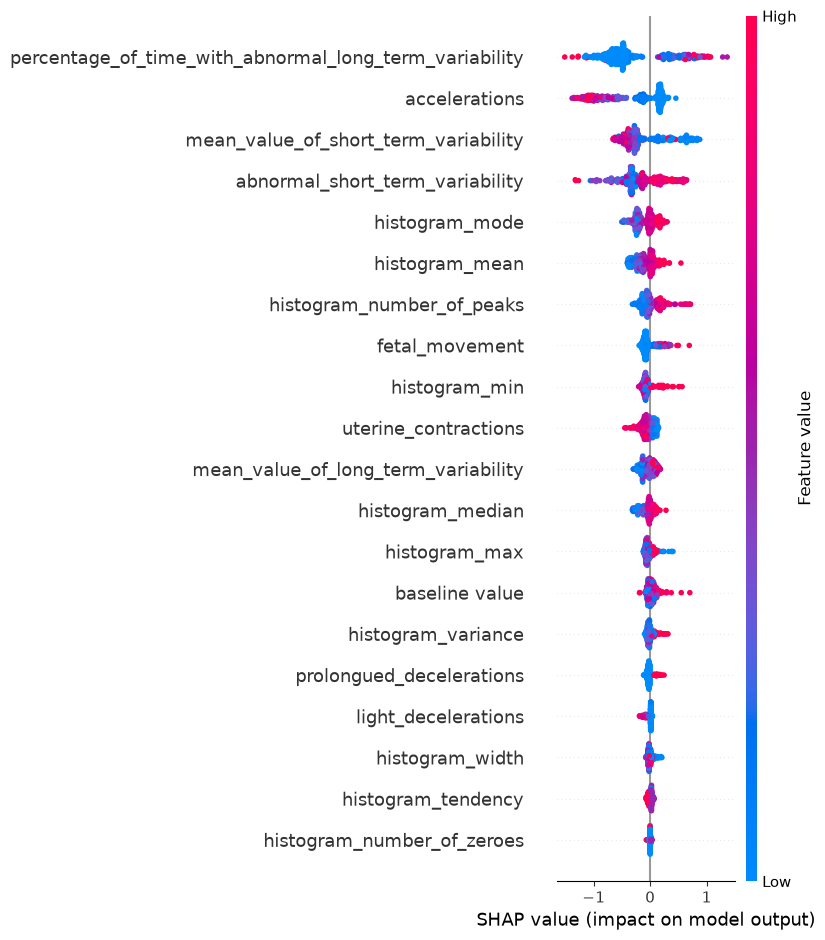


SHAP Summary Plot - Pathological


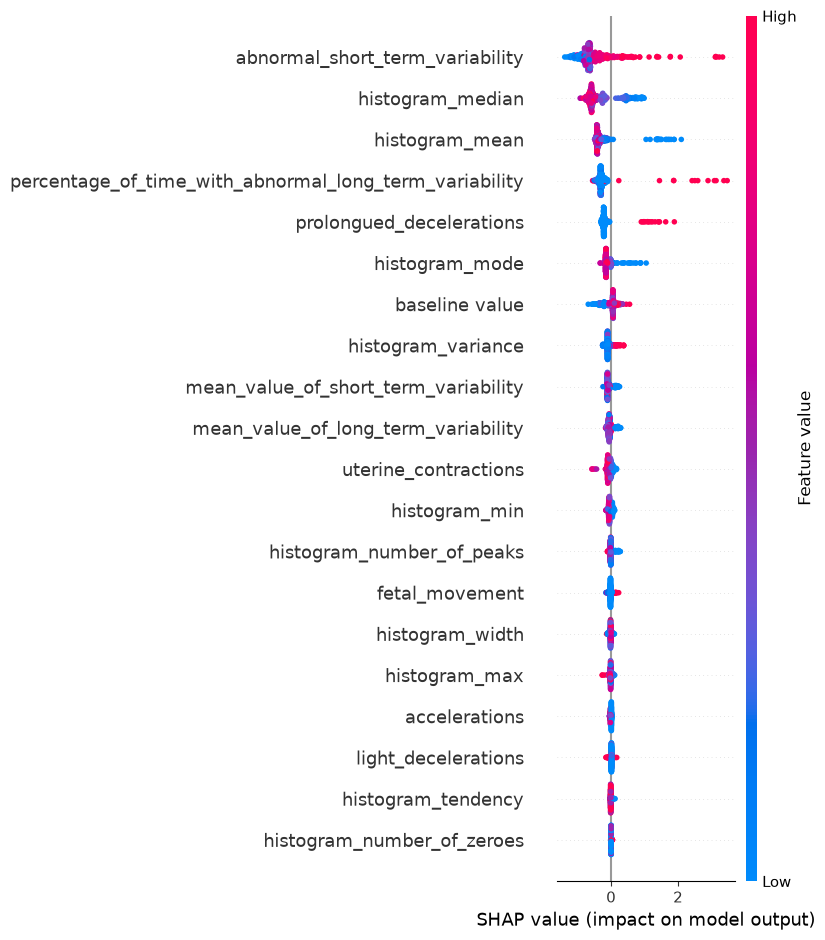

In [18]:
class_names = {
    0: "Normal",
    1: "Suspect",
    2: "Pathological"
}

for class_index, class_name in class_names.items():

    print(f"\nSHAP Summary Plot - {class_name}")

    shap.summary_plot(
        shap_explanation[:, :, class_index],
        X_explain,
        show=True
    )

## Pathological Class Feature Analysis

The Pathological class represents encoded class 2.

This section examines the features that contribute most strongly to the model's Pathological-class output.

The purpose is to understand the model's behavior when identifying this class, not to establish clinical risk factors or diagnostic criteria.

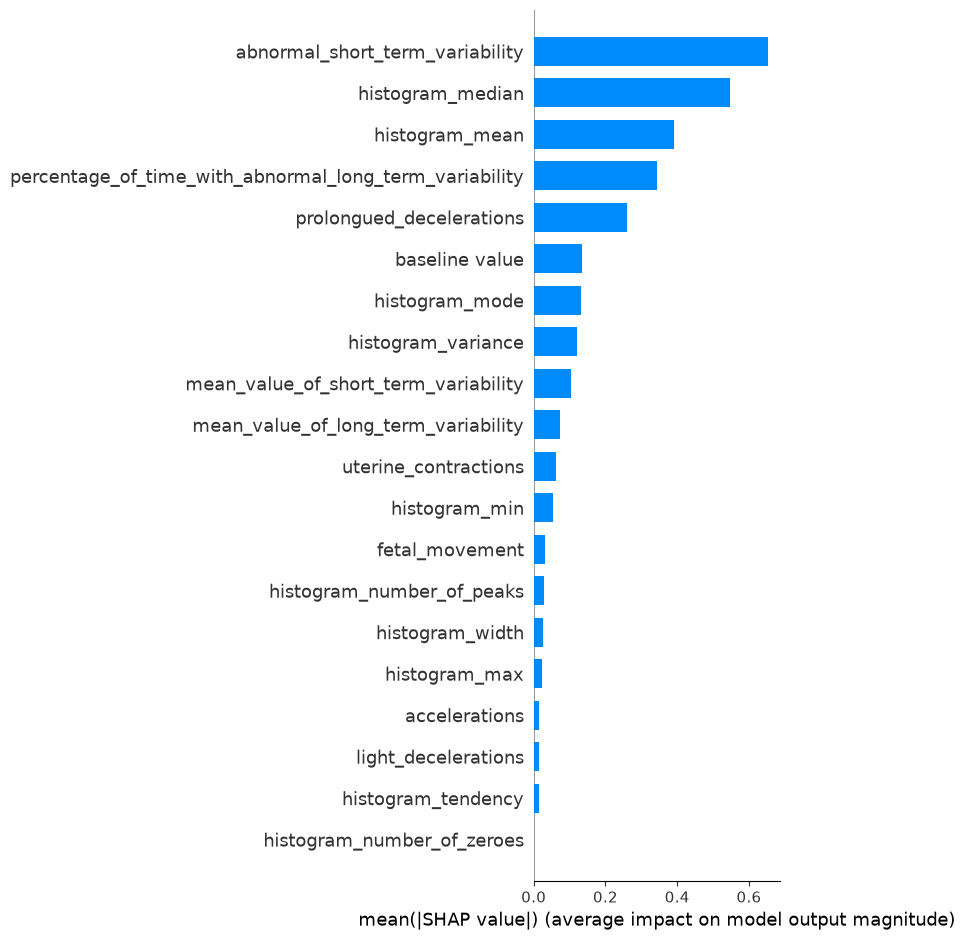

In [10]:
pathological_shap_values = shap_explanation[:, :, 2]

shap.summary_plot(
    pathological_shap_values,
    X_explain,
    plot_type="bar",
    show=True
)

## Individual Prediction Explanation

Global explanations show overall model behavior.

However, SHAP can also explain an individual prediction by showing how each feature contributes to the model's output for that particular observation.

For this example, we select a test record whose actual and predicted class are both Pathological.

In [19]:
prediction_results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
}, index=X_test.index)

correct_pathological = prediction_results[
    (prediction_results["Actual"] == 2) &
    (prediction_results["Predicted"] == 2)
]

print("Correctly predicted Pathological records:", len(correct_pathological))

Correctly predicted Pathological records: 33


In [20]:
if len(correct_pathological) == 0:
    print("No correctly predicted Pathological record found.")
else:
    selected_index = correct_pathological.index[0]

    selected_record = X_test.loc[[selected_index]]

    print("Selected record:")
    display(selected_record)

    print("Actual class:", class_names[int(y_test.loc[selected_index])])
    print("Predicted class:", class_names[int(y_pred[list(X_test.index).index(selected_index)])])

Selected record:


,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_width,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency
2,152.0,0.0,0.0,0.002,0.0,0.0,0.0,61.0,0.4,74.0,...,41.0,123.0,164.0,4.0,0.0,160.0,158.0,160.0,1.0,1.0


Actual class: Pathological
Predicted class: Pathological


## SHAP Waterfall Plot

A waterfall plot explains how individual features contribute to a particular prediction.

It starts from the model's baseline output and shows how feature contributions move the output toward or away from the selected class.

We use this visualization to understand the Pathological-class output for the selected observation.

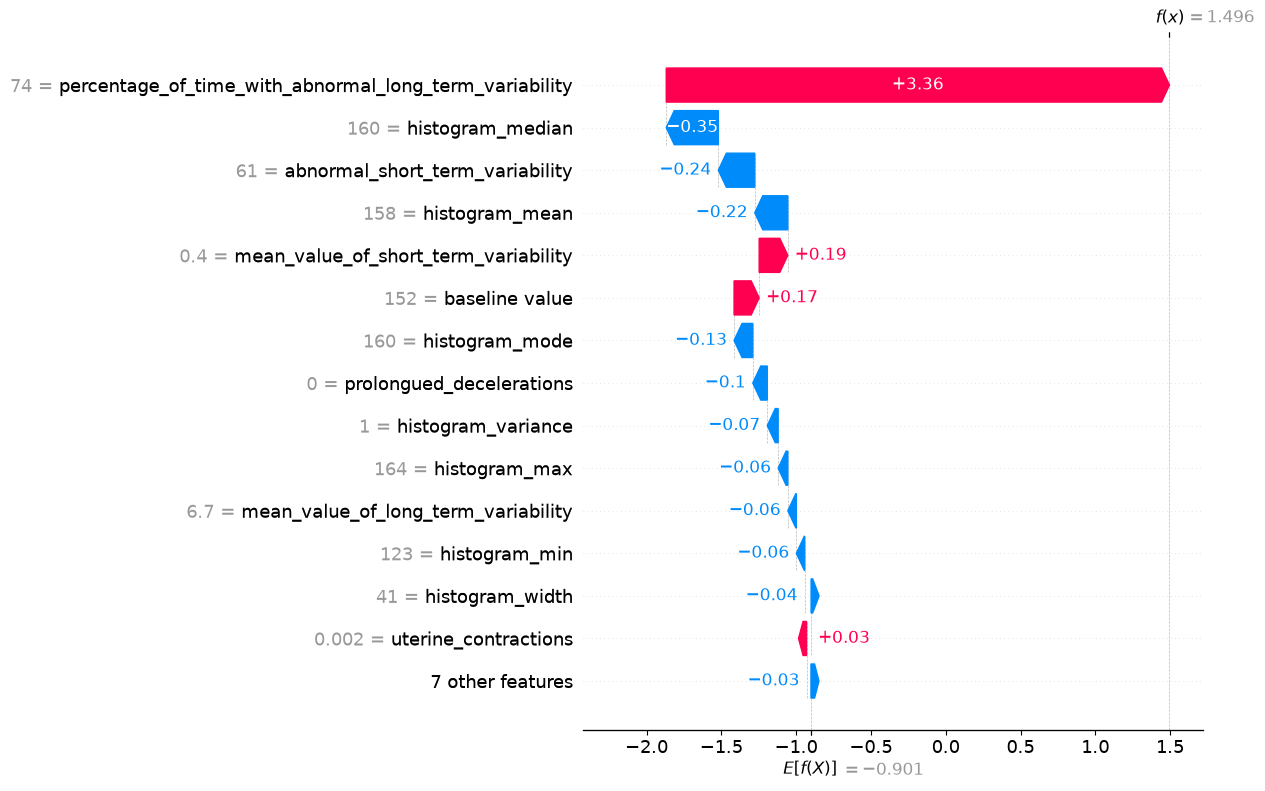

In [21]:
if len(correct_pathological) > 0:

    selected_position = list(X_explain.index).index(selected_index) if selected_index in X_explain.index else None

    if selected_position is None:
        print("Selected record is not part of the SHAP explanation sample.")
    else:
        local_explanation = shap_explanation[
            selected_position, :, 2
        ]

        shap.plots.waterfall(
            local_explanation,
            max_display=15
        )

## Final Observations

1. SHAP was used to understand the predictions made by the tuned XGBoost model.

2. Global feature importance helped identify the CTG features with the greatest overall influence on the model's outputs.

3. Class-wise SHAP analysis showed that feature contributions differ between Normal, Suspect, and Pathological predictions.

4. The Pathological-class analysis provided a closer look at the features influencing the model's output for that class.

5. The waterfall plot demonstrated how individual feature contributions combine to influence one selected prediction.

6. SHAP improves the interpretability of the machine-learning prototype. However, these explanations do not establish clinical validity or prove that a feature causes a particular fetal-health outcome.